# Activité Pratique N°4 : Architecture Transformer
**Comparaison des architectures séquentielles (RNN, LSTM, Transformer) sur série temporelle et découverte des modèles pré-entraînés (GPT et BERT).**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_squared_error

# Fixer les graines aléatoires pour la reproductibilité
np.random.seed(42)
torch.manual_seed(42)

# Configuration du périphérique (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Périphérique utilisé : {device}")

Périphérique utilisé : cpu


## 1. Génération de la série temporelle
Dans un premier temps, nous allons générer une série temporelle à partir de la fonction $y = \sin(x)$. Pour cela, nous allons créer 200 valeurs de $x$ comprises entre 0 et 20 à l'aide de `numpy.linspace`, puis calculer la valeur correspondante de $y$ avec la fonction sinus. Nous allons ensuite visualiser la série temporelle à l'aide de `matplotlib` afin d'observer son évolution.

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
C:\Users\dell\AppData\Local\Temp\ipykernel_14508\1007216630.py:8: SyntaxWarning: invalid escape sequence '\s'
  plt.title("Série temporelle générée : $y = \sin(x)$")


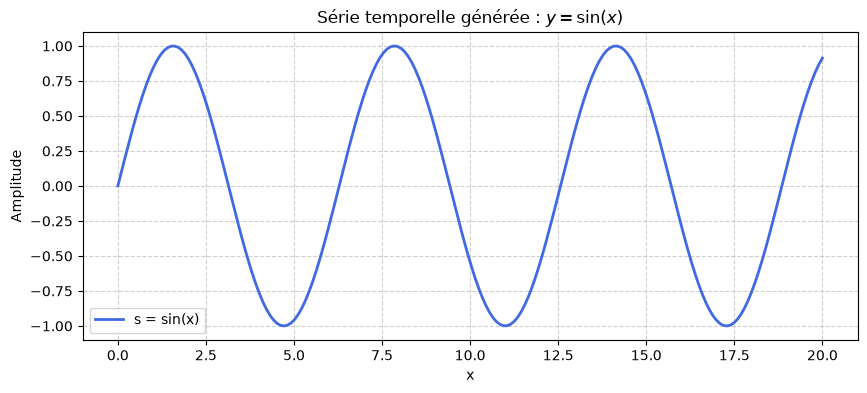

In [2]:
# Création de 200 valeurs entre 0 et 20
x = np.linspace(0, 20, 200)
s = np.sin(x)

# Visualisation de la série temporelle
plt.figure(figsize=(10, 4))
plt.plot(x, s, label="s = sin(x)", color="royalblue", linewidth=2)
plt.title("Série temporelle générée : $y = \sin(x)$")
plt.xlabel("x")
plt.ylabel("Amplitude")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

## 2. Préparation des séquences
Après avoir généré la série temporelle, nous allons transformer les données en séquences de longueur 10 afin de permettre au modèle de prédire la valeur suivante. Par exemple, la première séquence contient les valeurs $[S_0, S_1, \dots, S_9]$ et la valeur cible correspondante est $S_{10}$. La deuxième séquence contient $[S_1, S_2, \dots, S_{10}]$ et la cible est $S_{11}$. Cette opération est répétée jusqu'à obtenir l'ensemble des séquences. Nous obtenons ainsi une matrice $X$ contenant les séquences d'entrée et un vecteur $Y$ contenant les valeurs à prédire.

In [3]:
def create_sequences(data, seq_length=10):
    X, Y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        Y.append(data[i + seq_length])
    return np.array(X), np.array(Y)

SEQ_LENGTH = 10
X, Y = create_sequences(s, SEQ_LENGTH)

print(f"Forme de la matrice X : {X.shape}")
print(f"Forme du vecteur Y   : {Y.shape}")
print(f"Exemple 1 - Entrée X[0] : {np.round(X[0], 3)} -> Cible Y[0] : {Y[0]:.3f}")

Forme de la matrice X : (190, 10)
Forme du vecteur Y   : (190,)
Exemple 1 - Entrée X[0] : [0.    0.1   0.2   0.297 0.391 0.482 0.567 0.647 0.72  0.786] -> Cible Y[0] : 0.844


## 3. Séparation des données
Les séquences obtenues sont ensuite séparées en deux ensembles : un ensemble d'entraînement et un ensemble de test. Nous utilisons environ 80 % des données pour l'entraînement et 20 % pour le test. Comme il s'agit d'une série temporelle, nous conservons l'ordre des données et évitons de mélanger les observations entre l'entraînement et le test. Les données sont ensuite converties en tenseurs PyTorch afin de pouvoir les utiliser avec les différents modèles de Deep Learning.

In [4]:
train_size = int(len(X) * 0.8)

X_train_np, X_test_np = X[:train_size], X[train_size:]
Y_train_np, Y_test_np = Y[:train_size], Y[train_size:]

# Conversion en tenseurs PyTorch de forme (batch_size, seq_length, 1) pour X et (batch_size, 1) pour Y
X_train = torch.tensor(X_train_np, dtype=torch.float32).unsqueeze(-1).to(device)
Y_train = torch.tensor(Y_train_np, dtype=torch.float32).unsqueeze(-1).to(device)

X_test = torch.tensor(X_test_np, dtype=torch.float32).unsqueeze(-1).to(device)
Y_test = torch.tensor(Y_test_np, dtype=torch.float32).unsqueeze(-1).to(device)

print(f"X_train : {X_train.shape}, Y_train : {Y_train.shape}")
print(f"X_test  : {X_test.shape}, Y_test  : {Y_test.shape}")

X_train : torch.Size([152, 10, 1]), Y_train : torch.Size([152, 1])
X_test  : torch.Size([38, 10, 1]), Y_test  : torch.Size([38, 1])


## 4. Création et entraînement du modèle RNN
Dans cette étape, nous construisons un modèle RNN avec PyTorch afin de prédire la valeur suivante d'une séquence de 10 éléments. Le modèle reçoit une séquence de 10 valeurs et la traite progressivement à travers une couche RNN contenant 16 unités. Le dernier état de la séquence est ensuite envoyé vers une couche linéaire `Linear(16 -> 1)` qui produit la valeur prédite. Le modèle est entraîné avec la fonction de perte MSE (Mean Squared Error) et l'optimiseur Adam. Après l'entraînement, nous testons le modèle sur les données de test et comparons les valeurs réelles aux valeurs prédites.

MSE Test (RNN) : 0.000026


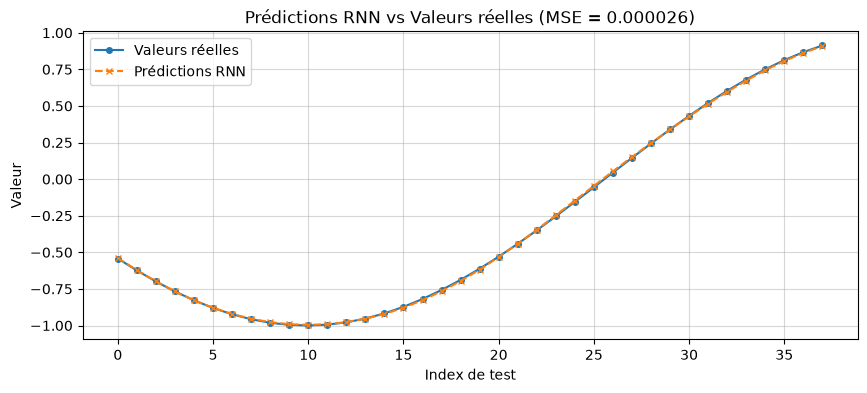

In [5]:
class RNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, output_size=1):
        super(RNNModel, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # out : (batch_size, seq_length, hidden_size)
        out, _ = self.rnn(x)
        # Récupération du dernier état caché de la séquence : out[:, -1, :]
        out = self.fc(out[:, -1, :])
        return out

def train_model(model, X_tr, Y_tr, epochs=300, lr=0.01):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        predictions = model(X_tr)
        loss = criterion(predictions, Y_tr)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

torch.manual_seed(42)
rnn_model = RNNModel().to(device)
rnn_losses = train_model(rnn_model, X_train, Y_train, epochs=300, lr=0.01)

# Évaluation sur l'ensemble de test
rnn_model.eval()
with torch.no_grad():
    rnn_preds = rnn_model(X_test).cpu().numpy()

rnn_mse = mean_squared_error(Y_test_np, rnn_preds)
print(f"MSE Test (RNN) : {rnn_mse:.6f}")

plt.figure(figsize=(10, 4))
plt.plot(Y_test_np, label="Valeurs réelles", marker="o", markersize=4)
plt.plot(rnn_preds, label="Prédictions RNN", linestyle="--", marker="x", markersize=4)
plt.title(f"Prédictions RNN vs Valeurs réelles (MSE = {rnn_mse:.6f})")
plt.xlabel("Index de test")
plt.ylabel("Valeur")
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

## 5. Création et entraînement du modèle LSTM
Nous réalisons ensuite la même tâche avec un modèle LSTM. L'objectif reste de prédire la valeur suivante à partir d'une séquence de 10 valeurs, mais la couche RNN est remplacée par une couche LSTM de 16 unités. Le LSTM possède des mécanismes de mémoire (état cellule $c_t$ et état caché $h_t$) permettant de mieux conserver certaines informations au cours de la séquence. Le modèle est entraîné avec la même fonction de perte MSE et l'optimiseur Adam. Une fois l'entraînement terminé, nous effectuons les prédictions sur l'ensemble de test et calculons l'erreur obtenue.

MSE Test (LSTM) : 0.000002


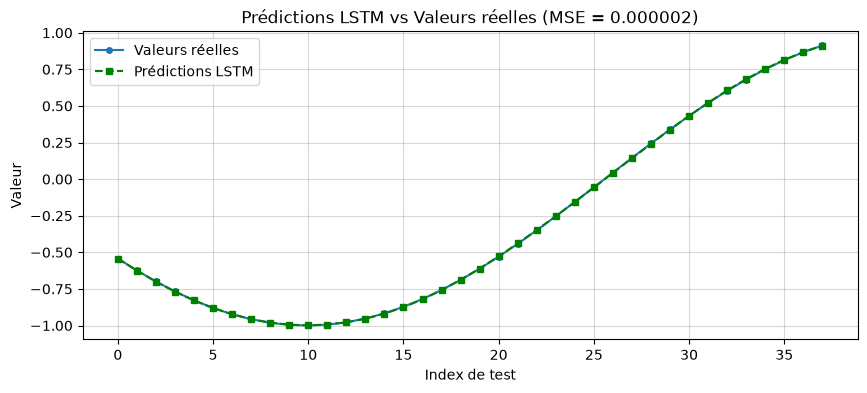

In [6]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, output_size=1):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, (hn, cn) = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

torch.manual_seed(42)
lstm_model = LSTMModel().to(device)
lstm_losses = train_model(lstm_model, X_train, Y_train, epochs=300, lr=0.01)

# Évaluation sur l'ensemble de test
lstm_model.eval()
with torch.no_grad():
    lstm_preds = lstm_model(X_test).cpu().numpy()

lstm_mse = mean_squared_error(Y_test_np, lstm_preds)
print(f"MSE Test (LSTM) : {lstm_mse:.6f}")

plt.figure(figsize=(10, 4))
plt.plot(Y_test_np, label="Valeurs réelles", marker="o", markersize=4)
plt.plot(lstm_preds, label="Prédictions LSTM", linestyle="--", marker="s", markersize=4, color="green")
plt.title(f"Prédictions LSTM vs Valeurs réelles (MSE = {lstm_mse:.6f})")
plt.xlabel("Index de test")
plt.ylabel("Valeur")
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

## 6. Création du modèle Transformer
Dans cette partie, nous construisons un modèle Transformer pour résoudre le même problème de prédiction de série temporelle :
1. Chaque valeur d'entrée (dimension 1) est transformée par une **projection linéaire** de dimension $1 \to 16$.
2. Nous ajoutons un **encodage positionnel** (`Positional Embedding`) pour les indices $0, 1, \dots, n-1$ afin de conserver l'ordre séquentiel.
3. Les représentations passent par un mécanisme de **Multi-Head Self-Attention** (2 têtes de dimension 16), suivi d'une **connexion résiduelle et d'une normalisation** (`Add & Norm`).
4. Le résultat traverse un réseau **Feed Forward** de type $16 \to 32 \to 16$ avec activation **ReLU**, suivi d'une seconde **connexion résiduelle et normalisation** (`Add & Norm`).
5. Enfin, nous récupérons la représentation du dernier élément de la séquence (`[:, -1, :]`) et l'envoyons vers une couche linéaire $16 \to 1$ pour obtenir la prédiction.

In [7]:
class TimeSeriesTransformer(nn.Module):
    def __init__(self, seq_length=10, d_model=16, nhead=2, dim_feedforward=32):
        super(TimeSeriesTransformer, self).__init__()
        # 1. Projection linéaire 1 -> 16
        self.input_projection = nn.Linear(1, d_model)
        
        # 2. Encodage positionnel apprenable pour les indices 0..seq_length-1
        self.pos_embedding = nn.Embedding(seq_length, d_model)
        
        # 3. Multi-Head Self-Attention (2 têtes, dimension 16)
        self.self_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=nhead, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        
        # 4. Réseau Feed Forward : 16 -> 32 -> 16 avec ReLU
        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Linear(dim_feedforward, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)
        
        # 5. Couche de sortie linéaire 16 -> 1
        self.fc_out = nn.Linear(d_model, 1)

    def forward(self, x):
        batch_size, seq_len, _ = x.shape
        
        # Projection linéaire + Encodage positionnel
        positions = torch.arange(0, seq_len, device=x.device).unsqueeze(0).expand(batch_size, seq_len)
        h = self.input_projection(x) + self.pos_embedding(positions)
        
        # Multi-Head Self-Attention + Connexion résiduelle + LayerNorm
        attn_output, _ = self.self_attn(h, h, h)
        h = self.norm1(h + attn_output)
        
        # Feed Forward + Connexion résiduelle + LayerNorm
        ffn_output = self.ffn(h)
        h = self.norm2(h + ffn_output)
        
        # Dernière représentation de la séquence [:, -1, :] -> Linear 16 -> 1
        out = self.fc_out(h[:, -1, :])
        return out

transformer_model = TimeSeriesTransformer(seq_length=SEQ_LENGTH, d_model=16, nhead=2, dim_feedforward=32).to(device)
print(transformer_model)

TimeSeriesTransformer(
  (input_projection): Linear(in_features=1, out_features=16, bias=True)
  (pos_embedding): Embedding(10, 16)
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
  )
  (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (ffn): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
  )
  (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc_out): Linear(in_features=16, out_features=1, bias=True)
)


## 7. Entraînement et test du Transformer
Après avoir défini l'architecture Transformer, nous allons l'entraîner sur les mêmes données utilisées pour le RNN et le LSTM avec la fonction de perte MSE et l'optimiseur Adam. Nous enregistrons la valeur de la perte afin de visualiser sa convergence, puis nous évaluons le modèle sur les données de test.

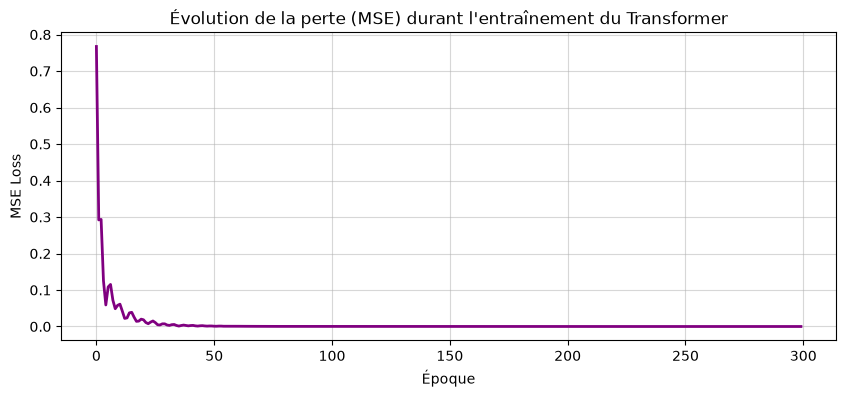

MSE Test (Transformer) : 0.000005


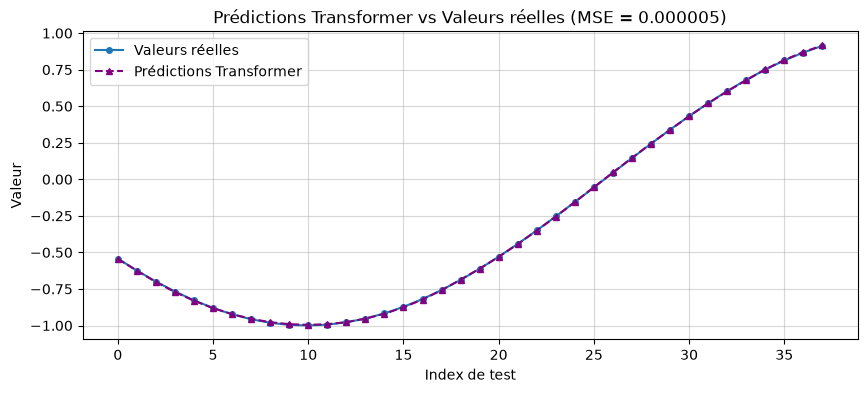

In [8]:
torch.manual_seed(42)
transformer_model = TimeSeriesTransformer(seq_length=SEQ_LENGTH, d_model=16, nhead=2, dim_feedforward=32).to(device)
transformer_losses = train_model(transformer_model, X_train, Y_train, epochs=300, lr=0.01)

# Visualisation de la courbe de perte (Loss)
plt.figure(figsize=(10, 4))
plt.plot(transformer_losses, color="purple", linewidth=2)
plt.title("Évolution de la perte (MSE) durant l'entraînement du Transformer")
plt.xlabel("Époque")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.5)
plt.show()

# Évaluation sur l'ensemble de test
transformer_model.eval()
with torch.no_grad():
    transformer_preds = transformer_model(X_test).cpu().numpy()

transformer_mse = mean_squared_error(Y_test_np, transformer_preds)
print(f"MSE Test (Transformer) : {transformer_mse:.6f}")

plt.figure(figsize=(10, 4))
plt.plot(Y_test_np, label="Valeurs réelles", marker="o", markersize=4)
plt.plot(transformer_preds, label="Prédictions Transformer", linestyle="--", marker="^", markersize=4, color="purple")
plt.title(f"Prédictions Transformer vs Valeurs réelles (MSE = {transformer_mse:.6f})")
plt.xlabel("Index de test")
plt.ylabel("Valeur")
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

## 8. Comparaison des modèles
Après avoir testé les trois modèles, nous comparons leurs valeurs de MSE ainsi que leurs courbes d'apprentissage et leurs prédictions sur l'ensemble de test.

=== Résumé des performances (MSE sur l'ensemble de test) ===
1. RNN         : 0.000026
2. LSTM        : 0.000002
3. Transformer : 0.000005


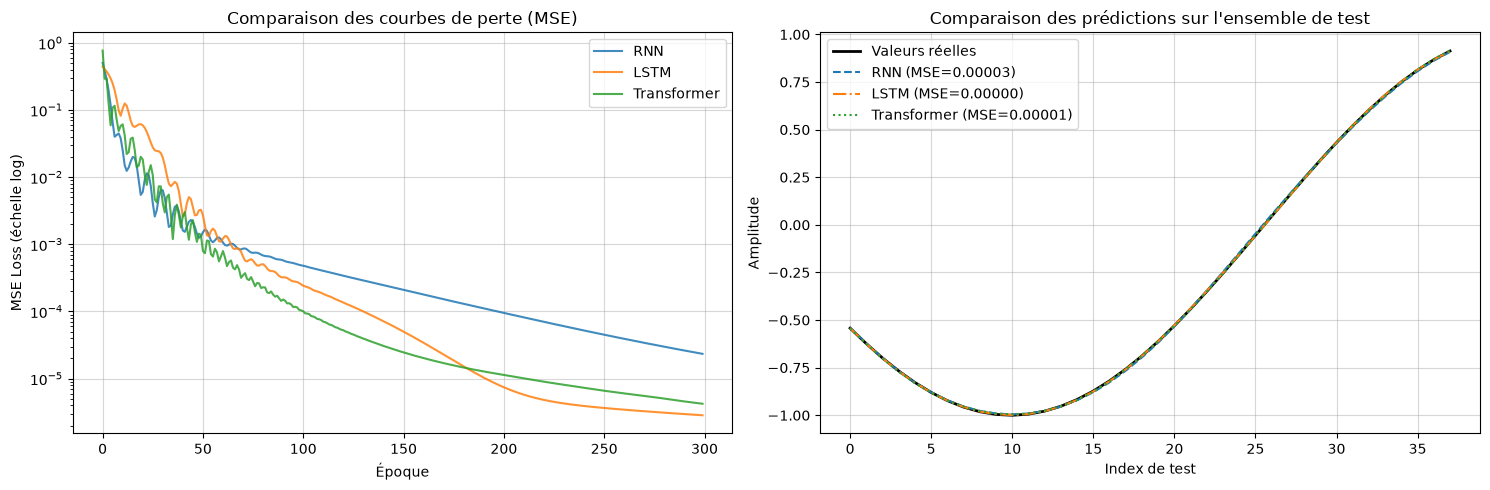

In [9]:
print("=== Résumé des performances (MSE sur l'ensemble de test) ===")
print(f"1. RNN         : {rnn_mse:.6f}")
print(f"2. LSTM        : {lstm_mse:.6f}")
print(f"3. Transformer : {transformer_mse:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1 : Évolution des pertes d'entraînement
axes[0].plot(rnn_losses, label="RNN", alpha=0.85)
axes[0].plot(lstm_losses, label="LSTM", alpha=0.85)
axes[0].plot(transformer_losses, label="Transformer", alpha=0.85)
axes[0].set_title("Comparaison des courbes de perte (MSE)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("MSE Loss (échelle log)")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.5)
axes[0].legend()

# Graphique 2 : Prédictions sur le jeu de test
axes[1].plot(Y_test_np, label="Valeurs réelles", color="black", linewidth=2)
axes[1].plot(rnn_preds, label=f"RNN (MSE={rnn_mse:.5f})", linestyle="--")
axes[1].plot(lstm_preds, label=f"LSTM (MSE={lstm_mse:.5f})", linestyle="-.")
axes[1].plot(transformer_preds, label=f"Transformer (MSE={transformer_mse:.5f})", linestyle=":")
axes[1].set_title("Comparaison des prédictions sur l'ensemble de test")
axes[1].set_xlabel("Index de test")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Utilisation d'un modèle GPT
Dans cette partie, nous passons de la prédiction numérique au traitement du langage naturel (NLP). Nous utilisons un modèle Transformer autorégressif de type GPT pré-entraîné (`distilgpt2` ou `gpt2` via la bibliothèque `transformers` de Hugging Face) afin de générer la suite du texte « Artificial intelligence can ».

In [10]:
# Décommenter la ligne suivante si la bibliothèque transformers n'est pas installée
# !pip install -q transformers

from transformers import pipeline, set_seed

set_seed(42)
# Chargement d'un modèle GPT léger (distilgpt2)
generator = pipeline("text-generation", model="distilgpt2")

prompt = "Artificial intelligence can"
outputs = generator(prompt, max_new_tokens=30, num_return_sequences=3, do_sample=True, top_k=50)

print(f"Texte d'entrée : '{prompt}'\n")
for i, out in enumerate(outputs, 1):
    print(f"Proposition {i} : {out['generated_text']}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Texte d'entrée : 'Artificial intelligence can'

Proposition 1 : Artificial intelligence can be a powerful tool to solve problems in the human realm.
Proposition 2 : Artificial intelligence can be manipulated to create artificial intelligence, but the artificial intelligence is not limited to a particular level of intelligence, which is why the AI is not able to
Proposition 3 : Artificial intelligence can be used for a variety of purposes, ranging from to to to create a personalized and personalized experience. For example, a virtual reality headset could be a


## 10. Utilisation d'un modèle BERT
Enfin, nous utilisons un modèle Transformer bidirectionnel de type BERT (`bert-base-uncased`) pour réaliser une tâche de prédiction de mot masqué (*Masked Language Modeling*). Contrairement à GPT, BERT analyse simultanément le contexte situé avant et après le token `[MASK]`.

In [11]:
unmasker = pipeline("fill-mask", model="bert-base-uncased")

sentences = [
    "Artificial intelligence is [MASK].",
    "Rabat is the [MASK] of Morocco."
]

for text in sentences:
    print(f"Phrase : {text}")
    predictions = unmasker(text, top_k=5)
    for pred in predictions:
        print(f"  - Mot prédit : {pred['token_str']:<15} | Probabilité : {pred['score']:.4f} | Phrase : {pred['sequence']}")
    print("-" * 75)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Phrase : Artificial intelligence is [MASK].
  - Mot prédit : possible        | Probabilité : 0.0553 | Phrase : artificial intelligence is possible.
  - Mot prédit : important       | Probabilité : 0.0461 | Phrase : artificial intelligence is important.
  - Mot prédit : fundamental     | Probabilité : 0.0198 | Phrase : artificial intelligence is fundamental.
  - Mot prédit : good            | Probabilité : 0.0172 | Phrase : artificial intelligence is good.
  - Mot prédit : common          | Probabilité : 0.0153 | Phrase : artificial intelligence is common.
---------------------------------------------------------------------------
Phrase : Rabat is the [MASK] of Morocco.
  - Mot prédit : capital         | Probabilité : 0.9991 | Phrase : rabat is the capital of morocco.
  - Mot prédit : birthplace      | Probabilité : 0.0001 | Phrase : rabat is the birthplace of morocco.
  - Mot prédit : province        | Probabilité : 0.0001 | Phrase : rabat is the province of morocco.
  - Mot prédit : 

## 11. Conclusion
Dans ce TP, nous avons étudié plusieurs architectures utilisées pour traiter les données séquentielles. Nous avons commencé par entraîner un **RNN**, puis un **LSTM** et enfin un **Transformer** afin de prédire la valeur suivante d'une série temporelle générée avec la fonction $\sin(x)$. Nous avons ensuite découvert deux applications majeures des Transformers pré-entraînés dans le domaine du traitement du langage naturel : **GPT** (décodeur autorégressif) pour générer la suite d'un texte et **BERT** (encodeur bidirectionnel) pour prédire un mot masqué. Cette activité permet ainsi de comprendre l'évolution des architectures séquentielles, des réseaux récurrents vers les mécanismes d'attention et leurs applications modernes.